# General relativity 9: Cosmology

*Learning path: general relativity, part 9 of 9.* [Index](README.md) · Previous: [Gravitational waves](08-gravitational-waves.ipynb)

On the largest scales the universe looks the same everywhere and in every direction. General relativity then allows
only one kind of metric, one in which space as a whole expands. You will learn

* the Friedmann–Lemaître–Robertson–Walker (FLRW) metric and the scale factor $a(t)$ [1],
* what radiation, matter and a cosmological constant each do to the expansion, checked with Einstein's equations,
* how to compute the age of the universe, 13.8 billion years, from three numbers,
* when the cosmic microwave background was released.

This lesson uses a few words from cosmology; each is explained where it first appears: *scale factor*, *Hubble
parameter*, *redshift*, *density* and *pressure*, *critical density* and the *Omegas* ($\Omega$), *dark matter* and
*dark energy*. Units: we set the speed of light $c = 1$, so time and distance are measured in the same units (a year
and a light-year).

## 1. The expanding universe

### The scale factor

Picture galaxies as raisins in a rising loaf of bread. Each raisin stays put in the dough, but the dough between them
grows, so every raisin moves away from every other one. To describe this, give each galaxy fixed labels $(x, y, z)$,
like grid lines drawn on the dough (*comoving coordinates*), and let all distances be multiplied by a common factor
$a(t)$ that grows with time. That is the **scale factor**. By convention $a = 1$ today, so $a = 1/2$ means "when all
distances were half what they are now".

On the largest scales the universe is the same everywhere and in every direction, and then (for flat space, which is
what we observe) the metric must be the **FLRW metric** [1]:

$$ds^2 = -dt^2 + a(t)^2\left(dx^2 + dy^2 + dz^2\right)$$

Read it like the metrics in earlier lessons: a clock at fixed $(x, y, z)$ measures the time $t$ (the *cosmic time*,
time since the Big Bang), and the distance between two galaxies at the same $t$ is $a(t)$ times their coordinate
distance.

### Hubble's law

If two galaxies are a coordinate distance $\Delta x$ apart, their actual distance is $d = a\,\Delta x$, so it grows at
the speed $\dot d = \dot a\,\Delta x = (\dot a/a)\,d$. Every galaxy recedes at a speed proportional to its distance:

$$v = H d, \qquad H = \frac{\dot a}{a}$$

$H$ is the **Hubble parameter**, the expansion rate; its value today, $H_0$, is the *Hubble constant*. Astronomers
quote it in km/s per megaparsec (one megaparsec, Mpc, is 3.26 million light-years). Today $H_0 \approx 67.7$ km/s/Mpc [3],
so a galaxy 100 Mpc away moves away from us at about 6 770 km/s.

### Einstein's equations for the scale factor

What decides how $a(t)$ grows? Einstein's equations $G_{ab} = 8\pi G\,T_{ab}$ (part 3), with the universe filled evenly
with "stuff" of **density** $\rho$ (energy per volume) and **pressure** $p$. Galileo computes the left side for any
$a(t)$; `a(t)` is an unknown function and `d(a, t)` its derivative:

In [1]:
frw = metric([t x y z], [-1 0 0 0; 0 a(t)^2 0 0; 0 0 a(t)^2 0; 0 0 0 a(t)^2])
einsteintensor(frw)

$$ds^2 = -dt^2 + a\left(t\right)^{2}\, dx^2 + a\left(t\right)^{2}\, dy^2 + a\left(t\right)^{2}\, dz^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Einstein tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{t}{}_{t} &= \frac{3 \, a'\left(t\right)^{2}}{a\left(t\right)^{2}} \\
G{}_{x}{}_{x} &= - 2 \, a\left(t\right) \, a''\left(t\right) - a'\left(t\right)^{2} \\
G{}_{y}{}_{y} &= - 2 \, a\left(t\right) \, a''\left(t\right) - a'\left(t\right)^{2} \\
G{}_{z}{}_{z} &= - 2 \, a\left(t\right) \, a''\left(t\right) - a'\left(t\right)^{2}
\end{aligned}$$

> `einsteintensor`: Einstein tensor G_ab = R_ab - R g_ab / 2, and its trace.

For matter at rest in these coordinates the right side is $8\pi G\rho$ in the $tt$ component and $8\pi G\,p\,g_{xx}$ in
the space components. So, component by component:

* $tt$: $\;3\dot a^2/a^2 = 8\pi G\rho$, that is

$$H^2 = \frac{8\pi G}{3}\,\rho \qquad\text{(the Friedmann equation)}$$

* $xx$ (divided by $g_{xx} = a^2$): $\;-(2a\ddot a + \dot a^2)/a^2 = 8\pi G\,p$, which says how pressure changes the expansion.

The Friedmann equation is the one we will use: **the more stuff there is, the faster space expands**. To use it we need
to know how the density changes as the universe grows. That depends on what the stuff is, and the next three sections
find out by trying exact solutions. The recipe each time: guess an $a(t)$, let Galileo compute $G_{ab}$, and read off
$8\pi G\rho = G_{tt}$ and $8\pi G\,p = G_{xx}/g_{xx}$.

## 2. Radiation: $a = \sqrt t$

In the hot early universe, most of the energy was in light (radiation). Try $a = \sqrt t$, so $g_{xx} = a^2 = t$:

In [2]:
rad = metric([t x y z], [-1 0 0 0; 0 t 0 0; 0 0 t 0; 0 0 0 t])
einsteintensor(rad)

$$ds^2 = -dt^2 + t\, dx^2 + t\, dy^2 + t\, dz^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Einstein tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{t}{}_{t} &= \frac{3}{4 \, t^{2}} \\
G{}_{x}{}_{x} &= \frac{1}{4 \, t} \\
G{}_{y}{}_{y} &= \frac{1}{4 \, t} \\
G{}_{z}{}_{z} &= \frac{1}{4 \, t}
\end{aligned}$$

> `einsteintensor`: Einstein tensor G_ab = R_ab - R g_ab / 2, and its trace.

Reading off:

* density: $8\pi G\rho = G_{tt} = 3/(4t^2)$. Check with Friedmann: $H = \dot a/a = 1/(2t)$, and $3H^2 = 3/(4t^2)$. ✓
* pressure: $8\pi G\,p = G_{xx}/g_{xx} = (1/(4t))/t = 1/(4t^2)$, exactly $\rho/3$. That is the pressure of a gas of light.
* dilution: $\rho \propto 1/t^2$ and $a^4 = t^2$, so $\rho \propto 1/a^4$. Radiation thins out with the volume ($a^3$), and
  each photon is also stretched to a longer wavelength, which lowers its energy by another factor $a$.

## 3. Matter: $a \propto t^{2/3}$

For cold matter (*dust* in the jargon: galaxies, gas, dark matter, anything moving slowly) the solution is
$a \propto t^{2/3}$. It looks simplest with a different time coordinate, *conformal time* $\eta$, defined by
$dt = a\,d\eta$. Then $a = \eta^2$ and the metric is $a^2(-d\eta^2 + dx^2 + dy^2 + dz^2)$ with $a^2 = \eta^4$:

In [3]:
dust = metric([eta x y z], [-eta^4 0 0 0; 0 eta^4 0 0; 0 0 eta^4 0; 0 0 0 eta^4])
einsteintensor(dust)

$$ds^2 = -\eta^{4}\, d\eta^2 + \eta^{4}\, dx^2 + \eta^{4}\, dy^2 + \eta^{4}\, dz^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Einstein tensor** (coordinates $\eta$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{\eta}{}_{\eta} &= \frac{12}{\eta^{2}}
\end{aligned}$$

> `einsteintensor`: Einstein tensor G_ab = R_ab - R g_ab / 2, and its trace.

* pressure: only $G_{\eta\eta}$ is non-zero, so $p = 0$: dust has **no pressure**, as it should.
* density: in these coordinates $8\pi G\rho = G_{\eta\eta}/a^2 = (12/\eta^2)/\eta^4 = 12/\eta^6$, and $a^3 = \eta^6$, so
  $\rho \propto 1/a^3$. Matter just thins out with the volume.
* time: $t = \int a\,d\eta = \eta^3/3$, so $a = \eta^2 \propto t^{2/3}$.

## 4. A cosmological constant: $a = e^{Ht}$

What if the expansion rate $H$ is constant? Then $\dot a = Ha$, so $a = e^{Ht}$:

In [4]:
ds = metric([t x y z], [-1 0 0 0; 0 exp(2*H*t) 0 0; 0 0 exp(2*H*t) 0; 0 0 0 exp(2*H*t)])
einsteintensor(ds)

$$ds^2 = -dt^2 + e^{2 \, H \, t}\, dx^2 + e^{2 \, H \, t}\, dy^2 + e^{2 \, H \, t}\, dz^2$$

> `metric`: A metric with the given coordinates and components g_ab.

**Einstein tensor** (coordinates $t$, $x$, $y$, $z$)

$$\begin{aligned}
G{}_{t}{}_{t} &= 3 \, H^{2} \\
G{}_{x}{}_{x} &= -3 \, e^{2 \, H \, t} \, H^{2} \\
G{}_{y}{}_{y} &= -3 \, e^{2 \, H \, t} \, H^{2} \\
G{}_{z}{}_{z} &= -3 \, e^{2 \, H \, t} \, H^{2}
\end{aligned}$$

> `einsteintensor`: Einstein tensor G_ab = R_ab - R g_ab / 2, and its trace.

* density: $8\pi G\rho = 3H^2$, **constant**: this stuff does not thin out at all as space grows.
* pressure: $8\pi G\,p = G_{xx}/g_{xx} = -3H^2$, so $p = -\rho$: a **negative pressure**.

This is Einstein's cosmological constant $\Lambda$ (part 3), today called **dark energy**: an energy of empty space
itself. Because it doesn't dilute while matter does, it eventually wins, and then the expansion speeds up
exponentially.

So far: radiation $\rho \propto a^{-4}$, matter $\rho \propto a^{-3}$, dark energy $\rho$ = constant.

## 5. Our universe

### Critical density and the Omegas

The Friedmann equation today reads $H_0^2 = \tfrac{8\pi G}{3}\rho_0$. The density that makes this true, $\rho_c = 3H_0^2/(8\pi G)$,
is the **critical density** (about five hydrogen atoms per cubic metre). Cosmologists give each ingredient as a
fraction of it, $\Omega = \rho_\text{today}/\rho_c$. The measured values [3]:

* $\Omega_m = 0.31$, **matter**. Only about $0.05$ of it is ordinary matter (atoms); the rest, about $0.26$, is
  **dark matter**: matter we detect only by its gravity (more below).
* $\Omega_\Lambda = 0.69$, dark energy.
* $\Omega_r \approx 9\times10^{-5}$, radiation (the cosmic microwave background and neutrinos).

They add up to 1, which is what makes space flat. Each ingredient dilutes in its own way, so at scale factor $a$ the
total density is $\rho_c\,(\Omega_r/a^4 + \Omega_m/a^3 + \Omega_\Lambda)$. Put that into the Friedmann equation and divide
by $H_0^2 = \tfrac{8\pi G}{3}\rho_c$:

$$H = H_0\sqrt{\frac{\Omega_r}{a^4} + \frac{\Omega_m}{a^3} + \Omega_\Lambda}, \qquad \dot a = aH = H_0\, a\,\sqrt{\frac{\Omega_r}{a^4} + \frac{\Omega_m}{a^3} + \Omega_\Lambda}$$

This one equation is the whole history of the expansion.

### Who dominates when

Each term matters at a different time. Here is the share of each ingredient in the total density, as a function of
$\log_{10} a$ (so $-3$ means $a = 1/1000$, and $0$ is today):

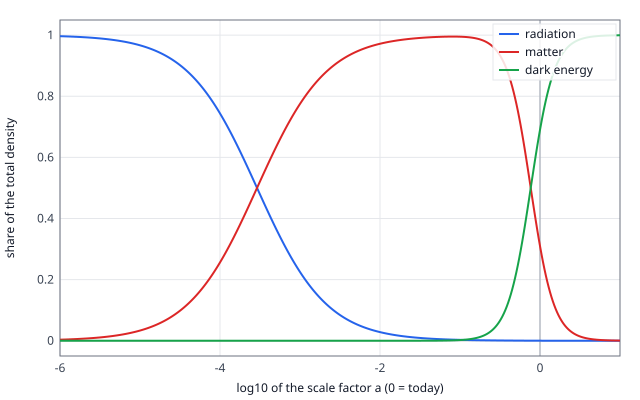

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
total = 9e-5/a^4 + 0.31/a^3 + 0.69;
fr = subs(9e-5/a^4/total, a, 10^L);
fm = subs(0.31/a^3/total, a, 10^L);
fl = subs(0.69/total, a, 10^L);
shares = legend(show(plot(fr, L, -6, 1), plot(fm, L, -6, 1), plot(fl, L, -6, 1)), "radiation", "matter", "dark energy");
labels(shares, "log10 of the scale factor a (0 = today)", "share of the total density")

First radiation dominates; matter takes over at $a \approx 3\times10^{-4}$ (the crossing on the left); dark energy takes
over at $a \approx 0.77$, only about 4 billion years ago.

### Units

$H_0$ is in km/s/Mpc, a speed per distance, so $1/H_0$ is a time, the *Hubble time*: roughly how long the universe has
been expanding. One Mpc is $3.0857\times10^{19}$ km and a billion years is $3.156\times10^{16}$ s, so
$1/(1\ \text{km/s/Mpc})$ is 977.8 billion years:

In [6]:
eval(3.0857e19/3.15576e16)
H0 = 67.7;
tH = eval(977.8/H0)

977.7993256774913

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

14.443131462333826

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

So $1/H_0$ is 14.4 billion years. Below we measure time in units of $1/H_0$ and multiply by `tH` at the end.

### The age of the universe

$\dot a = da/dt$, so $dt = da/\dot a$: the time to grow from $a$ to $a + da$. Adding these up from the Big Bang
($a = 0$) to today ($a = 1$) gives the age,

$$t_0 = \int_0^1 \frac{da}{\dot a} = \frac{1}{H_0}\int_0^1 \frac{da}{a\sqrt{\Omega_r/a^4 + \Omega_m/a^3 + \Omega_\Lambda}}$$

`integrate(f, a, 0, 1)` computes the integral of `f` over `a` from 0 to 1. There is no formula for this one, so Galileo
computes it numerically. The result is in units of $1/H_0$; times `tH` it is in billions of years:

In [7]:
age = integrate(1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69)), a, 0, 1)
eval(age*tH)

0.9548765679605511

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

13.791407801356378

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

**13.8 billion years**, the value quoted by the Planck satellite team (13.787 ± 0.020) [3]. Not bad for three numbers.

### The history of the expansion

Now solve $\dot a = H_0\,a\sqrt{\Omega_m/a^3 + \Omega_\Lambda}$ for $a(t)$ (dropping the radiation term, which only matters
in the first few hundred thousand years). This time we measure $t$ in billions of years, so the rate is
$k = H_0/977.8$ per billion years. The arguments of `odeplot`, in order:

| argument | what it is | here |
|---|---|---|
| `[k*a*sqrt(0.31/a^3 + 0.69)]` | the right-hand side, $da/dt$ | the Friedmann equation |
| `[a]` | the unknown | the scale factor |
| `t` | the independent variable | time in billions of years |
| `[0.001]` | the unknown at the start | $a = 0.001$, just after the Big Bang (at $a = 0$ itself the equation is infinite) |
| `0, 30` | start and end time | 0 to 30 billion years |
| `[t a]` | what to draw, horizontal and vertical | $t$ across, $a$ up |

For comparison, the same for a universe with matter only ($\Omega_m = 1$), which cosmologists assumed until 1998:

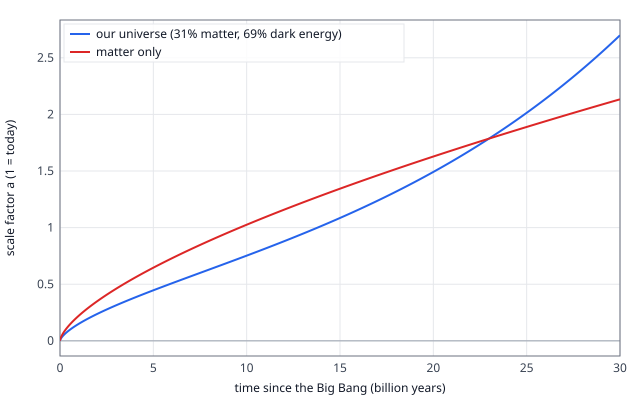

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
k = eval(H0/977.8);
ours = odeplot([k*a*sqrt(0.31/a^3 + 0.69)], [a], t, [0.001], 0, 30, [t a]);
matteronly = odeplot([k*a*sqrt(1/a^3)], [a], t, [0.001], 0, 30, [t a]);
labels(legend(show(ours, matteronly), "our universe (31% matter, 69% dark energy)", "matter only"), "time since the Big Bang (billion years)", "scale factor a (1 = today)")

Our universe reaches $a = 1$, today, at 13.8 billion years. At first its curve bends down (the expansion slows, as
in the matter-only universe), later it bends up (the expansion speeds up). The matter-only universe reaches $a = 1$
after only 9.6 billion years, which would make the universe younger than its oldest stars [4]. That conflict was one
of the hints that led to dark energy.

### When did the expansion start speeding up?

The expansion speed is $\dot a = H_0\sqrt{\Omega_m/a + \Omega_\Lambda a^2}$ (multiply $a$ into the square root). Matter
makes it fall as $a$ grows, dark energy makes it rise. Here it is against $a$:

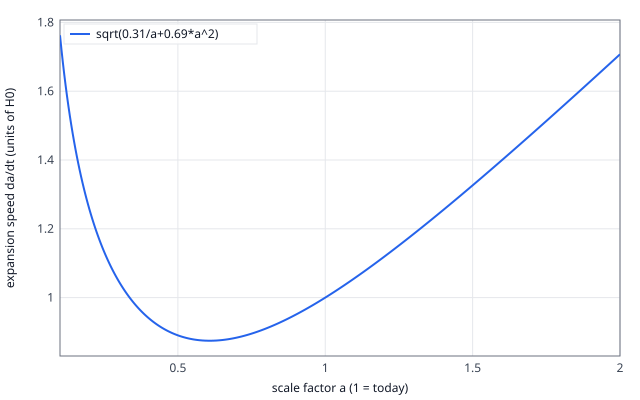

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
labels(plot(sqrt(0.31/a + 0.69*a^2), a, 0.1, 2), "scale factor a (1 = today)", "expansion speed da/dt (units of H0)")

The minimum is where the slowing down turns into speeding up. `fsolve(f, a, guess)` finds where `f` is zero, starting
from a guess; here `f` is the derivative of what is under the square root:

In [10]:
acc = fsolve(deriv(0.31/a + 0.69*a^2, a), a, 0.6)

0.6078935506225702

> `fsolve`: A numeric solution of f = 0 near the guess (Newton's method); for a system, Newton's method with the Jacobian.

At $a \approx 0.61$. Next we turn scale factors into something astronomers measure, redshift, and times.

### Looking back in time: redshift

Light that travels to us is stretched along with space. Light emitted when the scale factor was $a$ arrives with every
wavelength longer by a factor $1/a$. Astronomers write this as the **redshift** $z$: $1 + z = 1/a$. So the acceleration
began at $z = 1/0.61 - 1 \approx 0.65$.

The time since the Big Bang at scale factor $a_e$ is the same integral as the age, but stopping at $a_e$. For $a_e$ = the
start of acceleration, and for a galaxy at $z = 1$ ($a_e = 1/2$), and how long ago each was, in billions of years:

In [11]:
tacc = eval(integrate(1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69)), a, 0, acc)*tH)
eval(13.8 - tacc)
then = eval(integrate(1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69)), a, 0, 0.5)*tH)
eval(13.8 - then)

7.627636358793532

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

6.172363641206469

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

5.8563968640648065

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

7.943603135935194

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The expansion has been speeding up for about 6 billion years [2]. The light from a galaxy at $z = 1$ left it about
8 billion years ago, when the universe was under 6 billion years old.

### The cosmic microwave background

The early universe was a hot gas of free electrons and nuclei, and light could not travel far before bouncing off an
electron: the universe was opaque, like fog. When it cooled enough for electrons and nuclei to combine into hydrogen
atoms, at $z \approx 1090$ [3], it suddenly became transparent. The light released then still fills space: the
**cosmic microwave background** (CMB), now at 2.725 K [5]. Stretching the wavelengths by $1/a$ lowers the temperature by
the same factor, so $T = 2.725\,(1 + z)$. The temperature at release, in kelvin, and the age of the universe then, in
years:

In [12]:
eval(2.725*1091)
eval(integrate(1/(a*sqrt(9e-5/a^4 + 0.31/a^3 + 0.69)), a, 0, 1/1091)*tH*1e9)

2972.975

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

372930.8160817231

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

About 3 000 K, as hot as the surface of a cool star, about 370 000 years after the Big Bang. (Here the radiation term
matters, which is why we kept it in the integral.)

### Is dark matter the aether of our time?

It is a fair question. Twice before, astronomers saw a planet move "wrongly". In 1846 Le Verrier explained Uranus's
wobble with an unseen planet, and Neptune was found where he predicted it [7]: new *matter*. In 1859 he tried the same
for Mercury's orbit and predicted the planet Vulcan, which does not exist; the answer was new *gravity*, general
relativity (part 5). Dark matter is the Neptune-style answer to a set of anomalies. What makes most physicists take it
seriously is that very different observations ask for the same amount of it: the speeds of galaxies in clusters [8],
the rotation of galaxies [9], gravitational lensing, including a collision of two clusters where the lensing mass and
the visible gas have separated [10], and the pattern in the CMB, which needs $\Omega_m \approx 0.31$ but only $0.05$ in
atoms [3]. The Vulcan-style alternative, modified gravity (for example MOND), fits galaxy rotation well but has trouble
with clusters and the CMB. Until a dark matter particle is detected directly, though, the question stays open.

## Summary

* The FLRW metric $-dt^2 + a(t)^2\,d\vec x^2$ describes a uniform expanding universe; $H = \dot a/a$ is the expansion
  rate, and Hubble's law $v = Hd$ follows.
* Einstein's equations give the Friedmann equation $H^2 = \tfrac{8\pi G}{3}\rho$, and from exact solutions:
  $\rho \propto a^{-4}$ and $p = \rho/3$ for radiation, $\rho \propto a^{-3}$ and $p = 0$ for matter, and constant $\rho$
  with $p = -\rho$ for a cosmological constant.
* With $H_0$, $\Omega_m$ and $\Omega_\Lambda$, the Friedmann equation gives an age of 13.8 billion years, an expansion that
  has been accelerating since $z \approx 0.65$, and the CMB released at about 3 000 K, 370 000 years after the Big Bang.

**This is the end of the general relativity path.** Everything here came from one idea, that gravity is the geometry
of spacetime, worked out with metrics, Christoffel symbols, geodesics and curvature: the tools of the
[differential geometry path](../differential-geometry/README.md).

## Sources

Numbers in square brackets in the text refer to this list.

1. A. Friedmann, "Über die Krümmung des Raumes", *Zeitschrift für Physik* **10**, 377–386 (1922), [doi:10.1007/BF01332580](https://doi.org/10.1007/BF01332580); G. Lemaître, *Annales de la Société Scientifique de Bruxelles* **47A**, 49–59 (1927); H. P. Robertson, *Astrophysical Journal* **82**, 284 (1935); A. G. Walker, *Proc. London Math. Soc.* **42**, 90 (1937).
2. A. G. Riess et al., *Astronomical Journal* **116**, 1009 (1998), [doi:10.1086/300499](https://doi.org/10.1086/300499); S. Perlmutter et al., *Astrophysical Journal* **517**, 565 (1999), [doi:10.1086/307221](https://doi.org/10.1086/307221).
3. Planck Collaboration, "Planck 2018 results. VI. Cosmological parameters", *Astronomy & Astrophysics* **641**, A6 (2020): H₀ = 67.66, Ω_m = 0.3111, Ω_Λ = 0.6889, age 13.787 Gyr, z* = 1089.9. [doi:10.1051/0004-6361/201833910](https://doi.org/10.1051/0004-6361/201833910)
4. L. M. Krauss and B. Chaboyer, "Age estimates of globular clusters in the Milky Way: constraints on cosmology", *Science* **299**, 65–69 (2003): oldest clusters at least 11.2 Gyr. [doi:10.1126/science.1075631](https://doi.org/10.1126/science.1075631)
5. D. J. Fixsen, "The temperature of the cosmic microwave background", *Astrophysical Journal* **707**, 916 (2009): 2.72548 ± 0.00057 K. [doi:10.1088/0004-637X/707/2/916](https://doi.org/10.1088/0004-637X/707/2/916)
6. S. M. Carroll, *Spacetime and Geometry: An Introduction to General Relativity*, Addison-Wesley (2004). Chapter 8 (cosmology).
7. J. G. Galle, "Account of the discovery of Le Verrier's planet Neptune, at Berlin, Sept. 23, 1846", *Monthly Notices of the Royal Astronomical Society* **7**, 153 (1846).
8. F. Zwicky, "Die Rotverschiebung von extragalaktischen Nebeln", *Helvetica Physica Acta* **6**, 110–127 (1933).
9. V. C. Rubin and W. K. Ford, "Rotation of the Andromeda Nebula from a spectroscopic survey of emission regions", *Astrophysical Journal* **159**, 379 (1970). [doi:10.1086/150317](https://doi.org/10.1086/150317)
10. D. Clowe et al., "A direct empirical proof of the existence of dark matter", *Astrophysical Journal* **648**, L109 (2006). [doi:10.1086/508162](https://doi.org/10.1086/508162)